In [60]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [61]:
df = pd.read_csv("netflix_titles.csv")

In [62]:
print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [63]:
print(df.isnull().sum())

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [64]:
df['country'] = df['country'].fillna("Unknow")

In [65]:
df['director'] = df['director'].fillna("Unknow")

In [66]:
df = df.dropna(subset=["date_added","rating"])

In [67]:
df["date_added"] =pd.to_datetime(df["date_added"].str.strip())

In [68]:
df["year_added"] = df["date_added"].dt.year

In [69]:
print(df["type"].value_counts)

<bound method IndexOpsMixin.value_counts of 0         Movie
1       TV Show
2       TV Show
3       TV Show
4       TV Show
         ...   
8802      Movie
8803    TV Show
8804      Movie
8805      Movie
8806      Movie
Name: type, Length: 8793, dtype: str>


<Axes: >

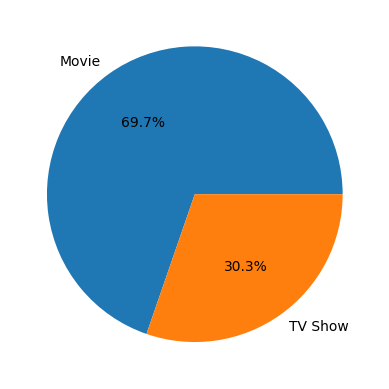

In [70]:
df['type'].value_counts().plot(kind="pie" , autopct="%1.1f%%")

<Axes: xlabel='year_added'>

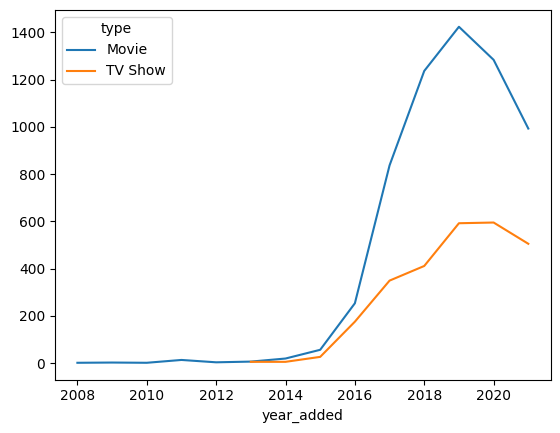

In [71]:
df.groupby(["year_added" , "type"]).size().unstack().plot(kind = "line")

In [72]:
top = df["country"].str.split(",").explode().value_counts().head(10)

<Axes: ylabel='country'>

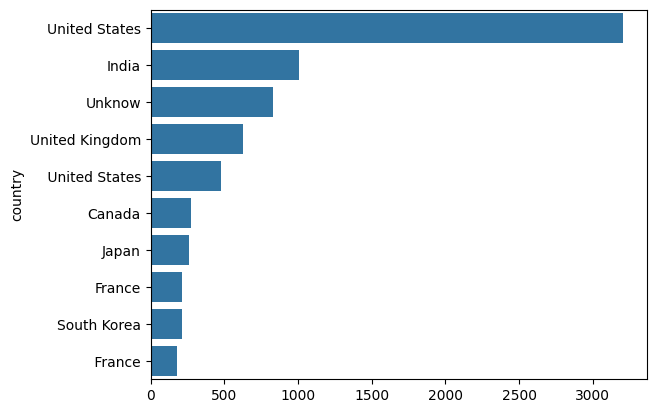

In [73]:
sns.barplot(x=top.values, y=top.index)

In [74]:
genres = df["listed_in"].str.split(",").explode().value_counts().head(10)

<Axes: ylabel='listed_in'>

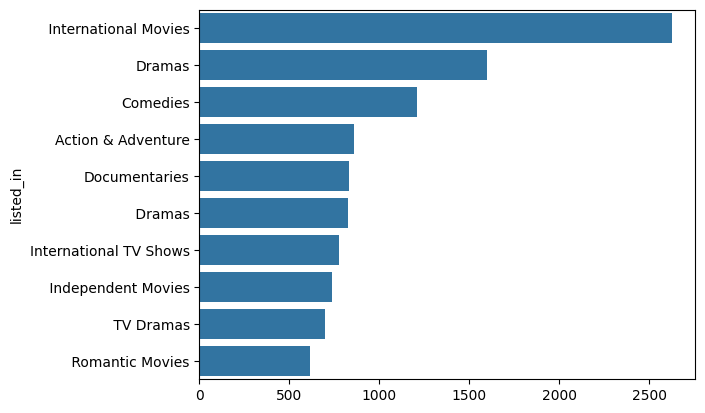

In [75]:
sns.barplot(x=genres.values,y=genres.index)

In [76]:
movies = df[df["type"] == "Movie"].copy()


In [88]:
movies["minutes"] =movies["duration"].str.replace(" min" ," ").astype(float)

<Axes: xlabel='minutes', ylabel='Count'>

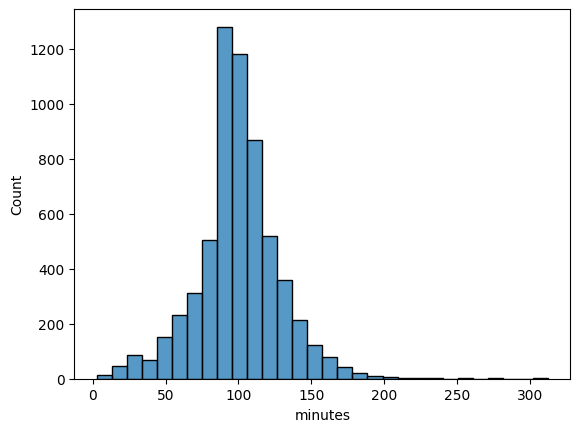

In [86]:
sns.histplot(movies["minutes"], bins=30)